In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

CITY = "Delhi"

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "regions"
OUTPUT_DIR = PROJECT_DIR / f"series2_outputs/{CITY.lower()}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(DATA_DIR / f"{CITY}_cell_year_2015_2025.csv")

data["year"] = pd.to_numeric(data["year"], errors="coerce")

VARIABLES = ["lst_c", "ndbi", "ndvi"]
YEARS = list(range(2015, 2026))
MAP_YEARS = [2015, 2020, 2025]

sns.set_theme(style="whitegrid")

print(f"City: {CITY}")
print(f"Records: {len(data):,}")
print(f"Unique grid cells: {data['grid_id'].nunique():,}")
print(f"Years present: {sorted(data['year'].dropna().unique().astype(int))}")
print(f"Output directory: {OUTPUT_DIR}")
display(data.head())


City: Delhi
Records: 134,508
Unique grid cells: 12,228
Years present: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Output directory: d:\sparkle\urban heat lockin\series2_outputs\delhi


,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix
0,Delhi_24695_11665,Delhi,Delhi,2015,38.822204,0.173816,0.078032,7.000000,22,0,Landsat 8
1,Delhi_24695_11665,Delhi,Delhi,2016,42.814601,0.143155,0.069131,6.000000,24,0,Landsat 8
2,Delhi_24695_11665,Delhi,Delhi,2017,45.421500,0.149542,0.079535,5.000000,22,0,Landsat 8
3,Delhi_24695_11665,Delhi,Delhi,2018,45.623410,0.160579,0.078166,4.000000,21,0,Landsat 8
4,Delhi_24695_11665,Delhi,Delhi,2019,50.711195,0.180171,0.068024,6.099167,21,0,Landsat 8


,records,unique_cells,mean_observations
year,,,
2015,12228,12228,10.953548
2016,12228,12228,9.133810
2017,12228,12228,9.674865
2018,12228,12228,8.436763
2019,12228,12228,9.628097
2020,12228,12228,9.769020
2021,12228,12228,8.202672
2022,12228,12228,21.274873
2023,12228,12228,13.771395


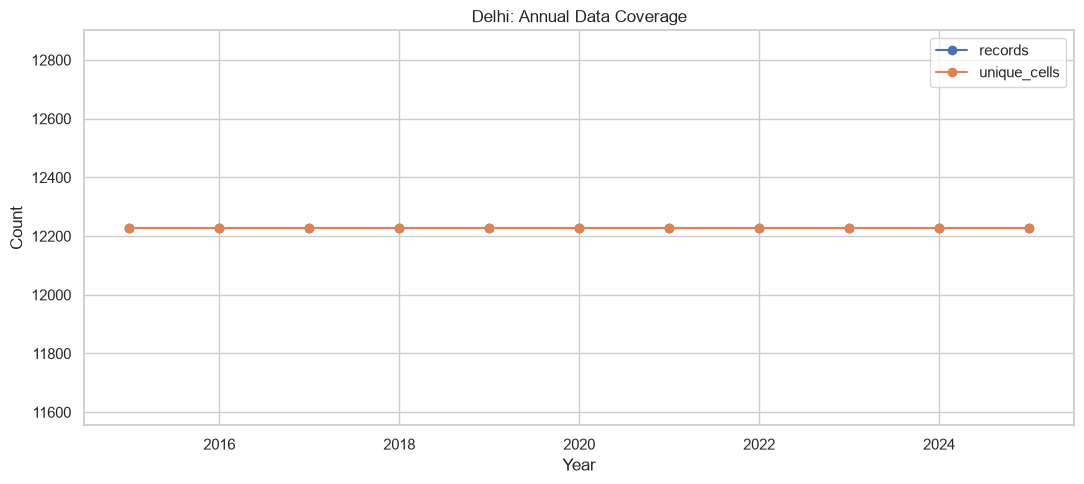

,missing_count,missing_percent
lst_c,0,0.0
ndbi,0,0.0
ndvi,0,0.0
n_obs_mean,0,0.0


In [2]:

# Number of records and unique grid cells per year
year_coverage = (
    data.groupby("year")
    .agg(
        records=("grid_id", "size"),
        unique_cells=("grid_id", "nunique"),
        mean_observations=("n_obs_mean", "mean")
    )
    .reindex(YEARS)
)

display(year_coverage)

ax = year_coverage[["records", "unique_cells"]].plot(
    figsize=(11, 5), marker="o"
)
ax.set_title(f"{CITY}: Annual Data Coverage")
ax.set_xlabel("Year")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_annual_coverage.png", dpi=200)
plt.show()

# Missing values
missing = data[VARIABLES + ["n_obs_mean"]].isna().sum().to_frame("missing_count")
missing["missing_percent"] = missing["missing_count"] / len(data) * 100
display(missing)

missing.to_csv(OUTPUT_DIR / "missing_values.csv")


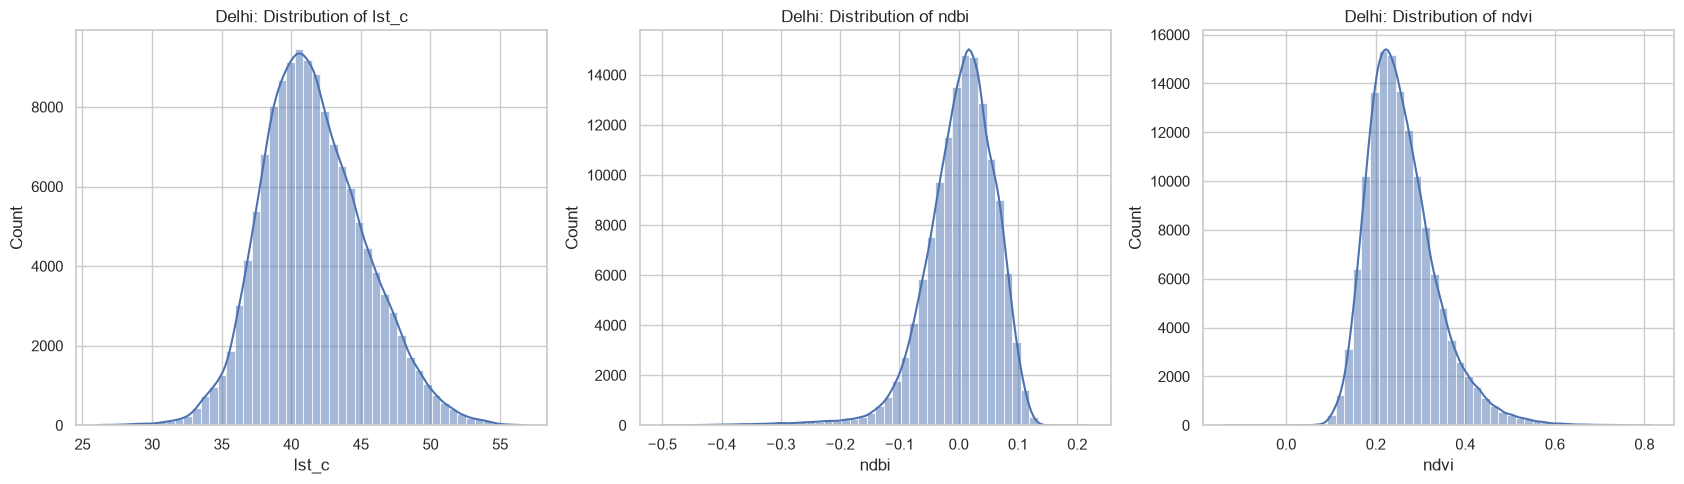

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
lst_c,134508.0,41.632747,3.727059,26.100203,33.677982,36.113900,39.034786,41.302838,44.016791,48.210647,51.139465,56.855662
ndbi,134508.0,0.003200,0.060161,-0.501913,-0.196309,-0.095092,-0.028874,0.009646,0.043545,0.085742,0.107571,0.220308
ndvi,134508.0,0.259073,0.078018,-0.137838,0.124973,0.155777,0.204436,0.246771,0.300375,0.405225,0.501831,0.818281


In [3]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, variable in zip(axes, VARIABLES):
    sns.histplot(
        data=data,
        x=variable,
        bins=50,
        kde=True,
        ax=ax
    )
    ax.set_title(f"{CITY}: Distribution of {variable}")
    ax.set_xlabel(variable)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_variable_distributions.png", dpi=200)
plt.show()

display(data[VARIABLES].describe(percentiles=[
    0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99
]).T)


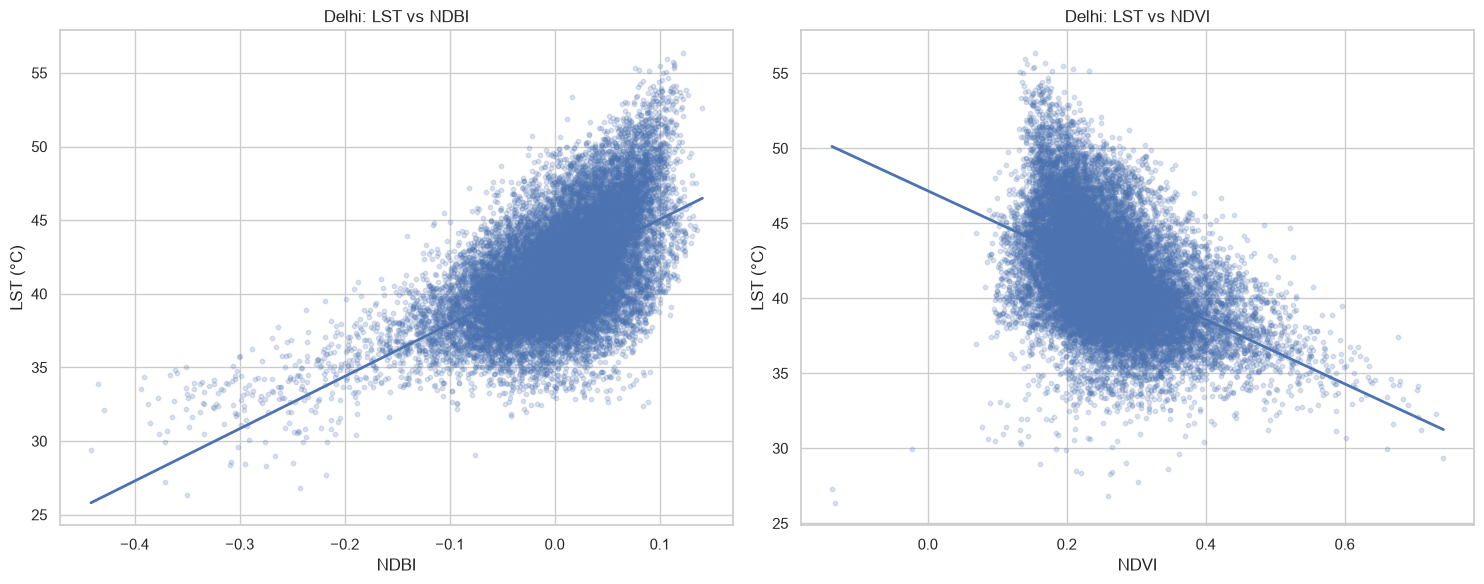

In [4]:

plot_data = data.dropna(subset=["lst_c", "ndbi", "ndvi"]).copy()

plot_sample = plot_data.sample(
    n=min(20000, len(plot_data)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI")
]:
    sns.regplot(
        data=plot_sample,
        x=xvar,
        y="lst_c",
        ax=ax,
        scatter_kws={"alpha": 0.2, "s": 10},
        line_kws={"linewidth": 2},
        ci=None
    )
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel(xvar.upper())
    ax.set_ylabel("LST (°C)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_lst_relationships.png", dpi=200)
plt.show()


In [5]:

PAIRS = [
    ("lst_c", "ndbi"),
    ("lst_c", "ndvi"),
    ("ndbi", "ndvi")
]

def calculate_correlations(df):
    results = []

    for x, y in PAIRS:
        pair = df[[x, y]].replace([np.inf, -np.inf], np.nan).dropna()
        n = len(pair)

        result = {
            "variable_1": x,
            "variable_2": y,
            "n": n,
            "pearson_r": np.nan,
            "pearson_p": np.nan,
            "spearman_rho": np.nan,
            "spearman_p": np.nan
        }

        if n >= 3 and pair[x].nunique() > 1 and pair[y].nunique() > 1:
            r, p = pearsonr(pair[x], pair[y])
            rho, sp = spearmanr(pair[x], pair[y])

            result.update({
                "pearson_r": r,
                "pearson_p": p,
                "spearman_rho": rho,
                "spearman_p": sp
            })

        results.append(result)

    return pd.DataFrame(results)

pooled_corr = calculate_correlations(data)
display(pooled_corr)
pooled_corr.to_csv(OUTPUT_DIR / "pooled_correlations.csv", index=False)

annual_corr = pd.concat(
    [
        calculate_correlations(group).assign(year=int(year))
        for year, group in data.groupby("year")
    ],
    ignore_index=True
)

display(annual_corr)
annual_corr.to_csv(OUTPUT_DIR / "annual_correlations.csv", index=False)


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,lst_c,ndbi,134508,0.573476,0.0,0.547947,0.0
1,lst_c,ndvi,134508,-0.446237,0.0,-0.458633,0.0
2,ndbi,ndvi,134508,-0.679319,0.0,-0.663568,0.0


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p,year
0,lst_c,ndbi,12228,0.567404,0.0,0.550516,0.0,2015
1,lst_c,ndvi,12228,-0.359845,0.0,-0.347398,0.0,2015
2,ndbi,ndvi,12228,-0.609328,0.0,-0.601906,0.0,2015
3,lst_c,ndbi,12228,0.518844,0.0,0.597780,0.0,2016
4,lst_c,ndvi,12228,-0.527999,0.0,-0.571286,0.0,2016
5,ndbi,ndvi,12228,-0.712643,0.0,-0.624685,0.0,2016
6,lst_c,ndbi,12228,0.643890,0.0,0.635633,0.0,2017
7,lst_c,ndvi,12228,-0.466850,0.0,-0.466853,0.0,2017
8,ndbi,ndvi,12228,-0.652584,0.0,-0.616088,0.0,2017
9,lst_c,ndbi,12228,0.684325,0.0,0.643948,0.0,2018


lst_c                                  ndbi                      \
           mean     median       std  count      mean    median       std   
year                                                                        
2015  38.679228  38.802724  2.459251  12228  0.016439  0.018634  0.053153   
2016  41.262951  41.549361  2.810648  12228  0.019658  0.026641  0.048769   
2017  40.884588  40.778956  2.906306  12228  0.004143  0.008325  0.055079   
2018  44.941208  44.615185  2.861420  12228  0.031928  0.035875  0.053011   
2019  47.083814  47.065938  2.935294  12228  0.021577  0.025887  0.056093   
2020  40.893711  40.508193  3.107354  12228 -0.014954 -0.007207  0.067087   
2021  40.518808  40.434974  2.543599  12228  0.001381  0.007835  0.055353   
2022  41.927523  41.840479  2.789460  12228 -0.020969 -0.015475  0.061252   
2023  38.102374  38.005822  2.287934  12228 -0.023111 -0.017734  0.065908   
2024  43.867275  43.996444  2.584853  12228  0.014650  0.022952  0.060163   
2025  39.798736  39.842358  2.238617  12228 -0.015542 -0.007816  0.051385   

                 ndvi                             
      count      mean    median       std  count  
year                                              
2015  12228  0.253810  0.244748  0.064400  12228  
2016  12228  0.219054  0.208120  0.061243  12228  
2017  12228  0.251437  0.247150  0.064899  12228  
2018  12228  0.212095  0.204274  0.055028  12228  
2019  12228  0.243517  0.237119  0.063723  12228  
2020  12228  0.289055  0.281487  0.084037  12228  
2021  12228  0.254107  0.245916  0.066595  12228  
2022  12228  0.279964  0.261855  0.086993  12228  
2023  12228  0.314267  0.302363  0.092909  12228  
2024  12228  0.247760  0.238985  0.067499  12228  
2025  12228  0.284732  0.271719  0.078597  12228

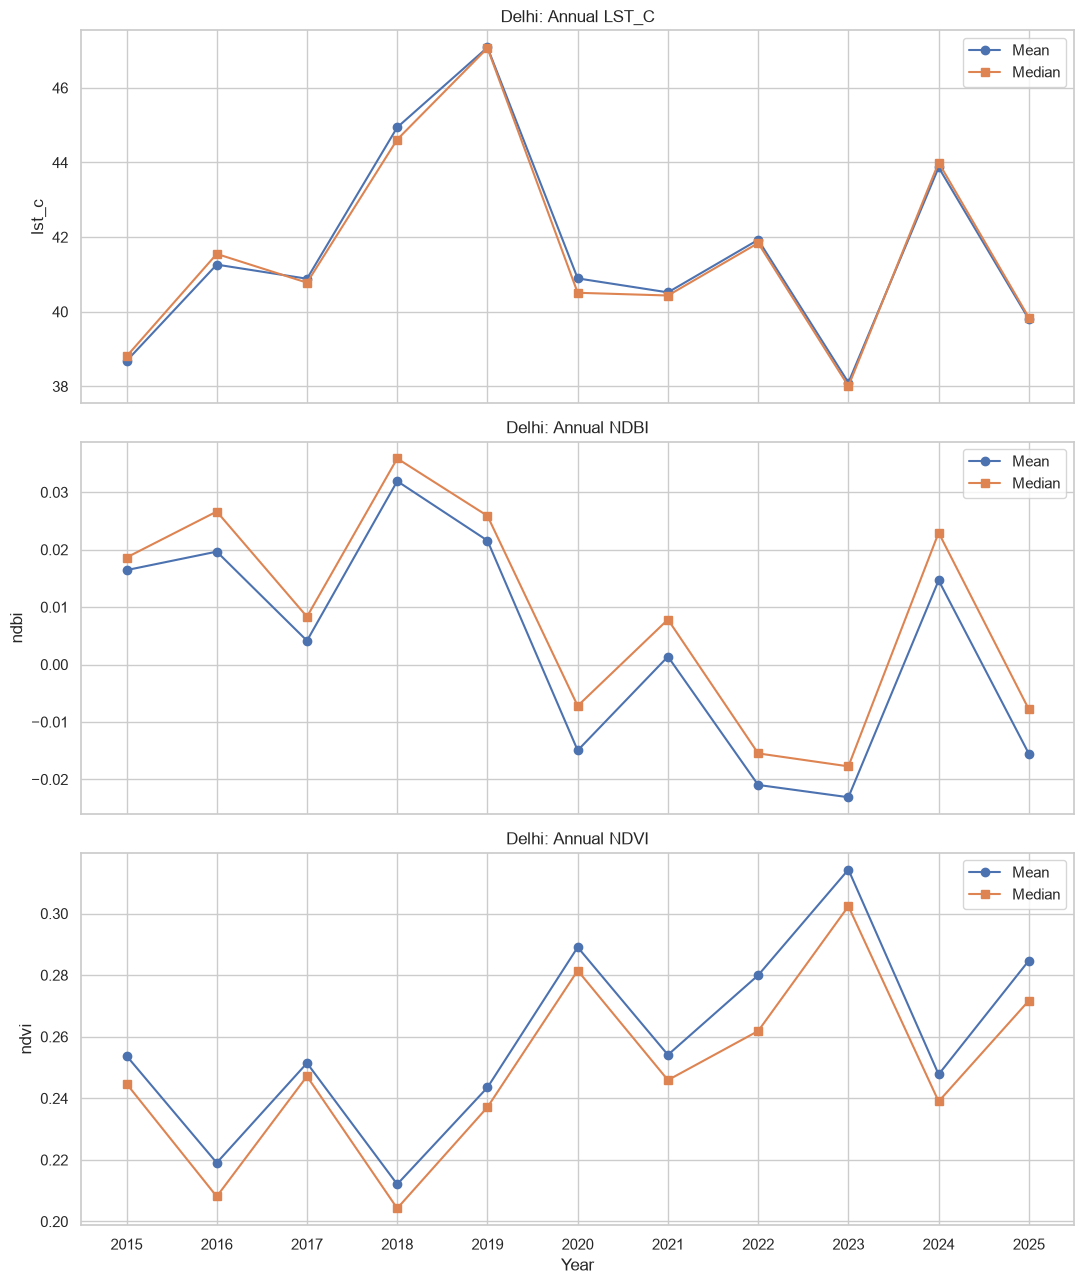

In [6]:

annual_stats = (
    data.groupby("year")[VARIABLES]
    .agg(["mean", "median", "std", "count"])
    .reindex(YEARS)
)

display(annual_stats)
annual_stats.to_csv(OUTPUT_DIR / "annual_summary_statistics.csv")

fig, axes = plt.subplots(3, 1, figsize=(11, 13), sharex=True)

for ax, variable in zip(axes, VARIABLES):
    stats = data.groupby("year")[variable].agg(["mean", "median"])

    ax.plot(stats.index, stats["mean"], marker="o", label="Mean")
    ax.plot(stats.index, stats["median"], marker="s", label="Median")

    ax.set_title(f"{CITY}: Annual {variable.upper()}")
    ax.set_ylabel(variable)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(YEARS)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_annual_trends.png", dpi=200)
plt.show()


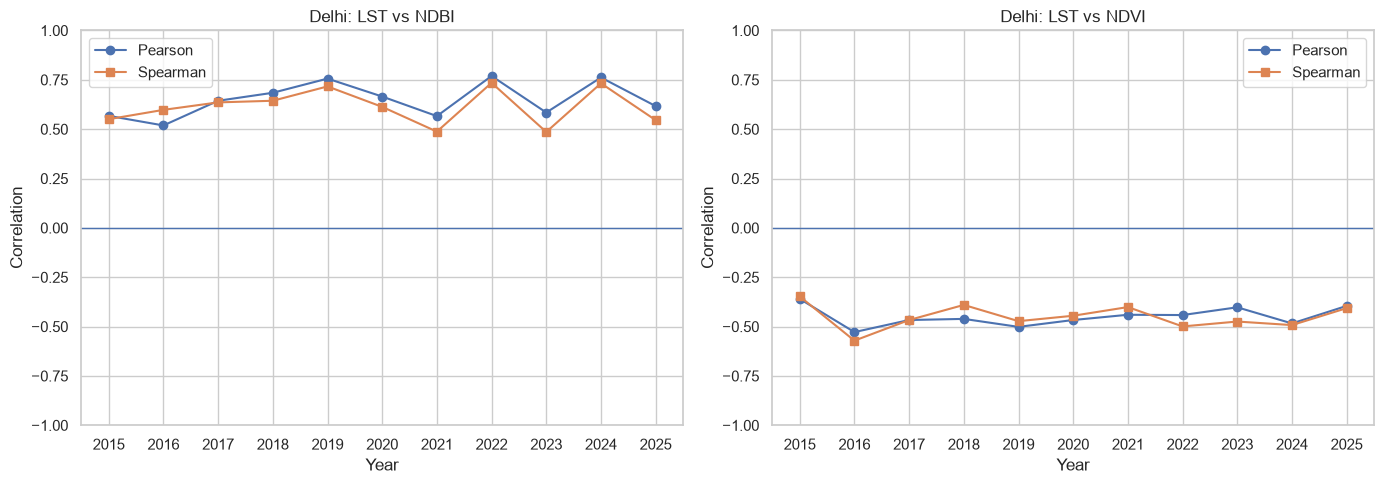

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI")
]:
    subset = annual_corr[
        (annual_corr["variable_1"] == "lst_c") &
        (annual_corr["variable_2"] == xvar)
    ]

    ax.plot(
        subset["year"], subset["pearson_r"],
        marker="o", label="Pearson"
    )
    ax.plot(
        subset["year"], subset["spearman_rho"],
        marker="s", label="Spearman"
    )
    ax.axhline(0, linewidth=1)
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Correlation")
    ax.set_ylim(-1, 1)
    ax.set_xticks(YEARS)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_annual_correlations.png", dpi=200)
plt.show()


Grid columns: ['grid_id', 'in_frac', 'city_id', 'geometry']
Grid CRS: PROJCS["WGS 84 / World Cylindrical Equal Area",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433]],PROJECTION["Cylindrical_Equal_Area"],PARAMETER["central_meridian",0],PARAMETER["standard_parallel_1",30],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["m",1],AXIS["X",EAST],AXIS["Y",NORTH]]
Number of grid cells: 12228


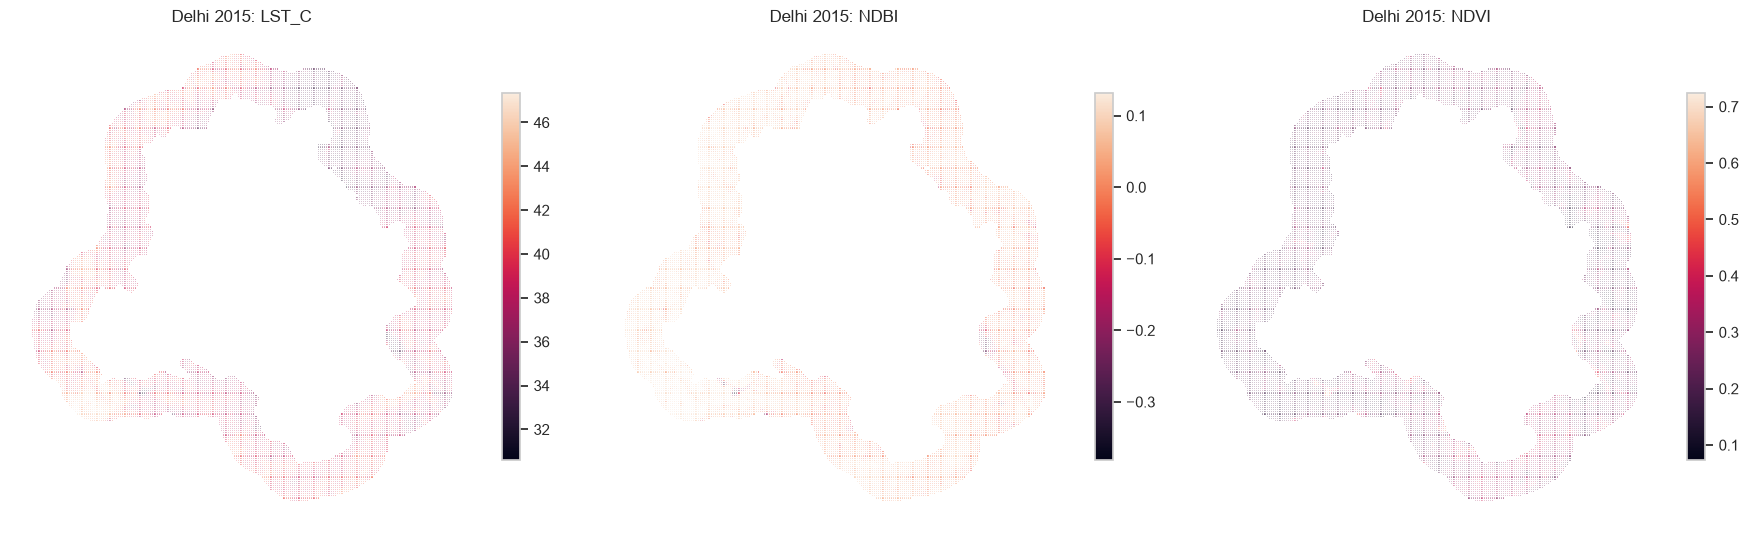

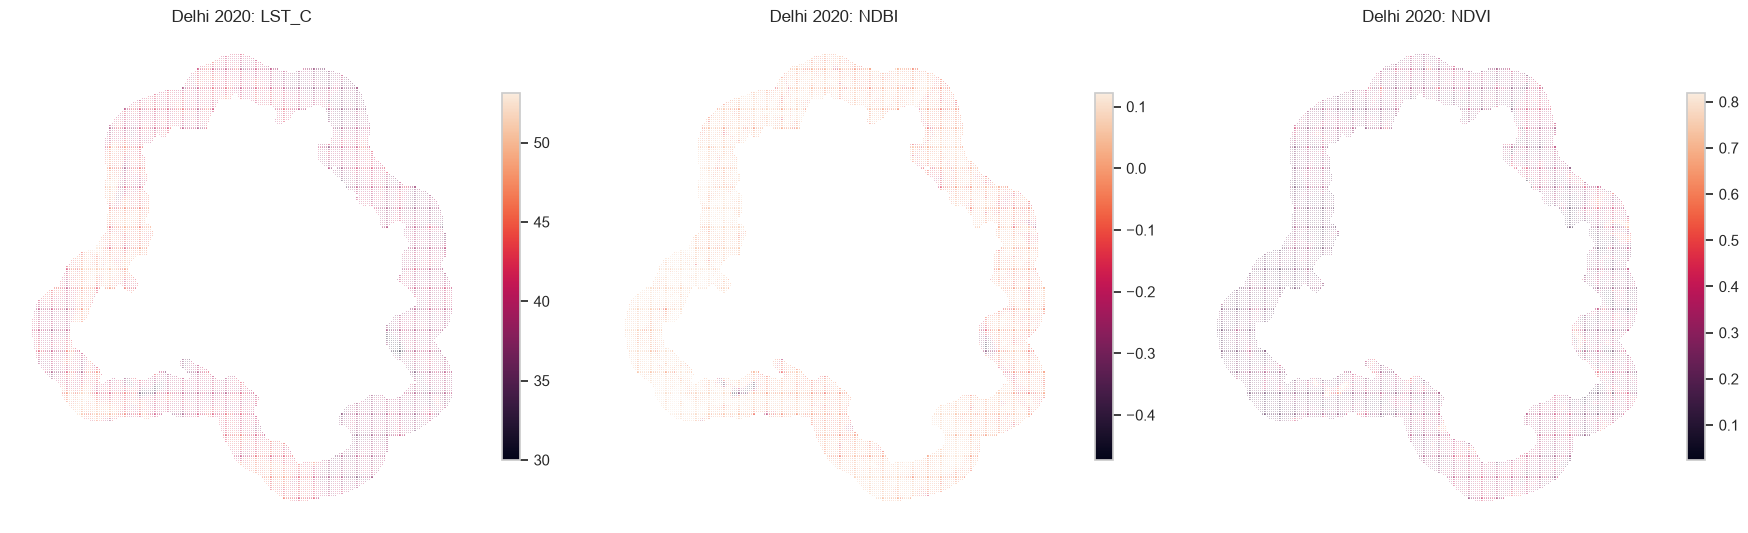

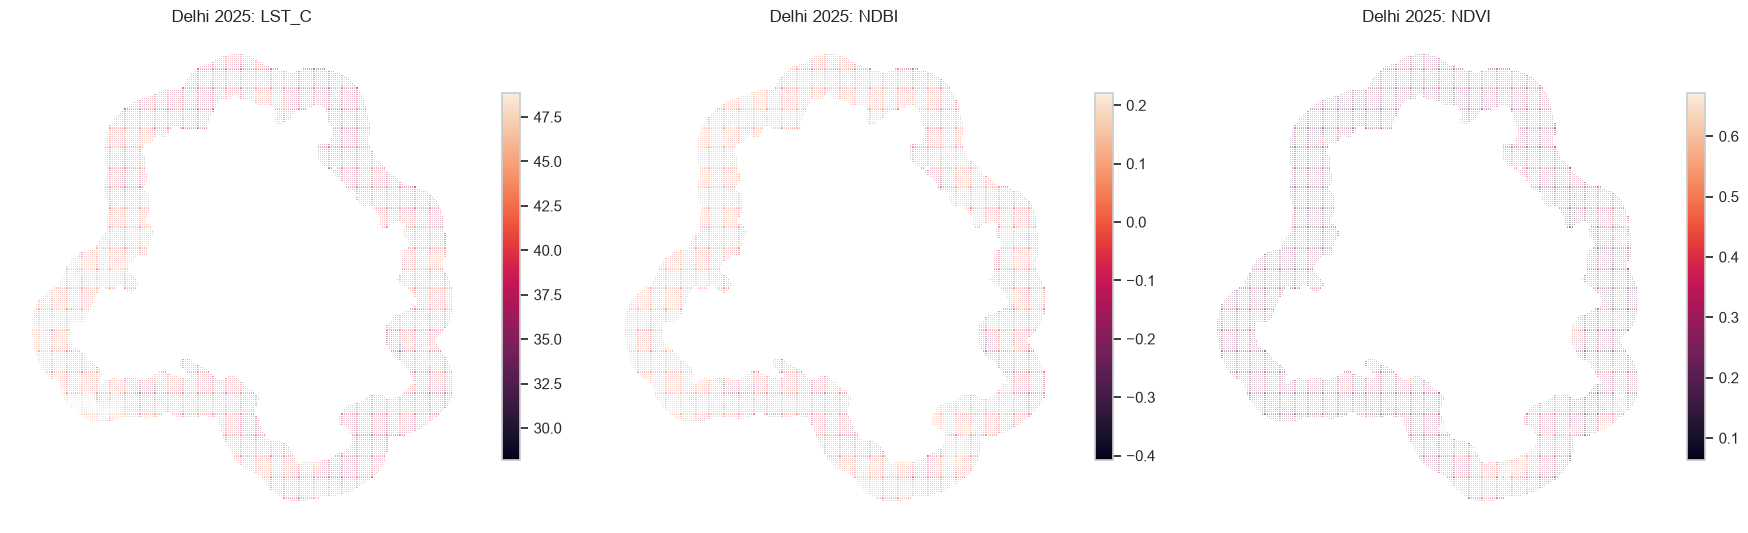

In [8]:

import geopandas as gpd
from pathlib import Path

# Change this path to your actual 300 m grid shapefile
SHAPEFILE_PATH = PROJECT_DIR / "grids" / f"{CITY}_Grid_300m.shp"

if not SHAPEFILE_PATH.exists():
    print(f"Shapefile not found: {SHAPEFILE_PATH}")
else:
    grid = gpd.read_file(SHAPEFILE_PATH)

    print("Grid columns:", grid.columns.tolist())
    print("Grid CRS:", grid.crs)
    print("Number of grid cells:", len(grid))

    if "grid_id" not in grid.columns:
        raise ValueError(
            "The shapefile has no grid_id column. "
            "Check its column names and identify the matching grid ID field."
        )

    grid["grid_id"] = grid["grid_id"].astype(str)
    data["grid_id"] = data["grid_id"].astype(str)

    if grid.crs is None:
        raise ValueError("The shapefile has no CRS defined.")

    grid = grid.to_crs("EPSG:4326")

    for year in MAP_YEARS:
        year_data = data.loc[
            data["year"] == year,
            ["grid_id"] + VARIABLES
        ]

        joined = grid.merge(
            year_data,
            on="grid_id",
            how="left",
            validate="one_to_one"
        )

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        for ax, variable in zip(axes, VARIABLES):
            joined.plot(
                column=variable,
                ax=ax,
                legend=True,
                missing_kwds={
                    "color": "lightgrey",
                    "label": "No data"
                },
                legend_kwds={"shrink": 0.65}
            )
            ax.set_title(f"{CITY} {year}: {variable.upper()}")
            ax.set_axis_off()

        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"map_{CITY}_{year}.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()
